# 00 — Leia primeiro: mapa, fluxo e pilares do projeto

**Risco de abandono escolar em Roraima** · PIBIC/UERR (Edital 35/2026) e artigo da disciplina de Mineração de
Dados · orientador: Prof. Bruno Cesar Barreto Figueiredo · estado de referência: **10/11/2026**.

Esta pasta (`Dados-do-Projeto/Contexto do Projeto/`) atualiza os relatórios 00 a 07 de
`Relatórios do Projeto/` (escritos até 14/10/2026) com as decisões e descobertas feitas depois. Ela também
junta num só lugar o fluxo dos dados, as figuras e os pilares do projeto (ferramentas e decisões). Os
relatórios antigos ficam onde estão, como histórico: não foram alterados.

| Notebook | Substitui | Cobre |
|---|---|---|
| `00_leia_primeiro` | `00_LEIA_PRIMEIRO.md` | este mapa: fluxo, pilares, ferramentas, linha do tempo, ordem de leitura |
| `01_projeto` | `01_PROJETO.md` | pergunta (antes e agora), escopo, pessoas, estado atual, resultados em uma página, glossário |
| `02_dados` | `02_DADOS.md` | fontes, procedência, as duas bases, universo, ausência, desfechos, enriquecimento |
| `03_metodologia` | `03_METODOLOGIA.md` | desenho t → t+1, cenários e blocos, regras, walk-forward, baselines, métricas, incerteza |
| `04_experimentos` | `04_EXPERIMENTOS.md` | histórico dos experimentos e do uso de 2024→2025, Etapa 2 ano a ano, hipóteses refutadas, TDI separável, matriz E0–E9 |
| `05_referencias` | `05_REFERENCIAS.md` | Almeida & Mussato (2023) anotado, proposta do orientador, fontes, método, contexto (a conferir) |
| `06_decisoes_problemas_perguntas` | `06_DECISOES_PROBLEMAS_PERGUNTAS.md` | as três numerações de decisões, vigentes e revertidas, divergências nos documentos, problemas, perguntas |
| `07_planos` | `07_PLANOS.md` | plano de outubro, estratégia do orientador, critérios da fase 1, Plano avançado, caminhos que dependem de decisão |

**Divergências.** Ao preparar os notebooks 04 a 07 apareceram quatro frases dos documentos oficiais que a
evidência do próprio projeto contradiz. A principal: os documentos dizem que a transição 2024→2025 "nunca foi
usada para avaliar modelo", mas os notebooks de outubro a usaram como teste. Elas estão no notebook 06, §5,
com a correção proposta. **Nenhum documento oficial foi alterado:** a correção cabe à pesquisadora.

**Como ler os números.** Os notebooks **exibem, não calculam** (`abandono-escolar/CLAUDE.md` §4). Toda
contagem vem de um CSV gerado por código: os do `abandono-escolar/docs/`, os do `gustavo/saida/` e os desta
pasta (`tabelas/`, gerados por `gerar_tabelas.py`). As células só leem, filtram e desenham.

A classificação do estado de cada decisão, pergunta, experimento e passo de plano está em `registros/`. Ela
foi escrita à mão, uma linha por item e cada uma com a fonte; o código só a conta e confere o vocabulário.
Revise antes de citar.

Os níveis de evidência são os da síntese:

- **[FATO]:** verificável reexecutando código;
- **[MEDIDO]:** com intervalo e correção para testes múltiplos;
- **[PONTUAL]:** sem intervalo ou sem sobreviver à correção;
- **[EXPLORATÓRIO]:** olhou o desfecho de anos de teste;
- **[INTERPRETAÇÃO]:** leitura sem teste próprio;
- **[REFUTADO]**.

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
ENTRADAS = {
    "bases": TABELAS / "bases_dimensoes.csv",
    "manifesto": TABELAS / "manifesto_por_estagio.csv",
    "checks": TABELAS / "checks_gustavo.csv",
    "tempo": TABELAS / "linha_do_tempo_decisoes.csv",
    "req_oficial": OFICIAL / "requirements.txt",
    "req_dados": DADOS_DO_PROJETO / "requirements.txt",
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py" (da pasta Dados-do-Projeto)')
bases = pd.read_csv(ENTRADAS["bases"]).set_index("base")
manifesto = pd.read_csv(ENTRADAS["manifesto"]).set_index("estagio")
checks = pd.read_csv(ENTRADAS["checks"])
tempo = pd.read_csv(ENTRADAS["tempo"], parse_dates=["data"])
bases

,linhas,colunas,ano_min,ano_max,escolas
base,,,,,
oficial (abandono-escolar),6054,59,2019,2025,934
base_atual (gustavo),12597,55,2007,2025,988


## 1. O projeto em uma frase

> Identificar **qual informação** sobre uma escola pública de Roraima no ano *t* carrega sinal sobre o
> **abandono escolar em *t*+1**, separadamente nos anos finais do fundamental (AF) e no ensino médio (EM). A
> previsão é o **instrumento** dessa medida: Recall@K contra baselines fixados antes, com intervalo e correção
> de Holm.

O uso pretendido é priorizar escolas para diagnóstico e apoio, nunca ranquear nem punir. A unidade é a
escola-ano: a base é agregada por escola e não prevê aluno.

Até 02/11/2026 a pergunta era "estimar a taxa de abandono em *t*+1" (relatório 01 de outubro). A troca foi
decisão da pesquisadora e foi aplicada sem a consulta prévia ao orientador que o `CLAUDE.md` §6 exige. Está
registrada como falha de processo (`DECISOES.md`, 2026-11-02, "Mudança de objetivo"), e a validação do
orientador está pendente.

## 2. Fluxo dos dados: dois pipelines, uma avaliação

O projeto tem dois pipelines de dados, que só se encontram dentro da avaliação:

- **o oficial** (`abandono-escolar`) é *largo*: 7 anos, com TDI, ATU e IED por escola-ano, e toda a
  procedência dos arquivos;
- **o do Gustavo** (`gustavo/`) é *comprido*: 19 anos de rendimento mais a infraestrutura do prédio.

O painel da avaliação junta os dois **em memória**, sem gravar uma terceira base. Cada seta do diagrama
abaixo tem um teste ou uma comparação que a confere.

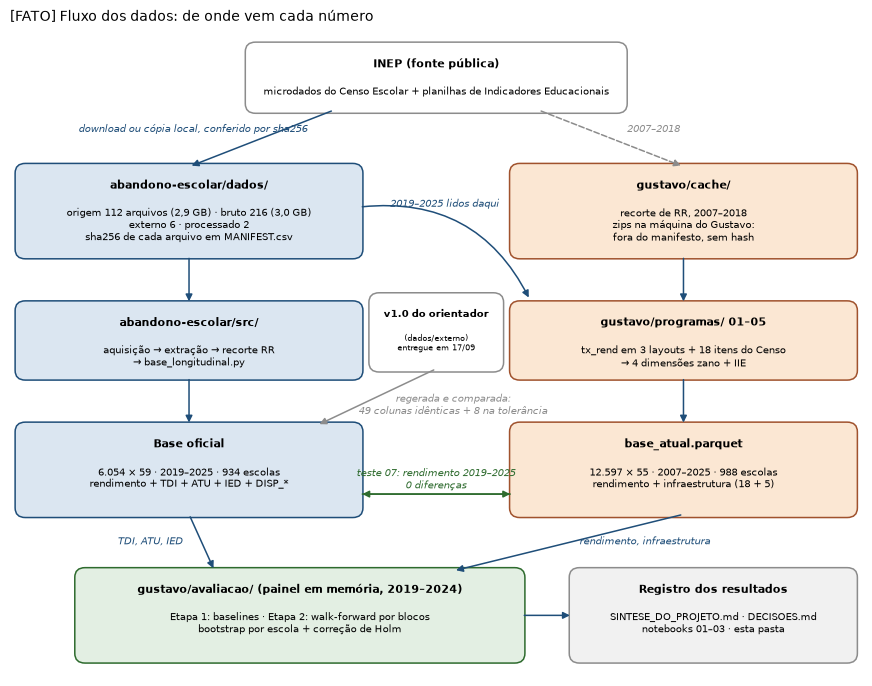

In [3]:
def dims(nome):
    r = bases.loc[nome]
    return f"{r.linhas:,} × {r.colunas}".replace(",", "."), f"{r.ano_min}–{r.ano_max}", f"{r.escolas} escolas"

lin_o, anos_o, esc_o = dims("oficial (abandono-escolar)")
lin_g, anos_g, esc_g = dims("base_atual (gustavo)")
arq = manifesto["arquivos"]
gb = manifesto["gb"].map(lambda v: f"{v:.1f}".replace(".", ","))

fig, ax = plt.subplots(figsize=(11, 8.4))
D.tela(ax, 100, 80)
inep = D.caixa(ax, 28, 70, 44, 8, "INEP (fonte pública)\nmicrodados do Censo Escolar + planilhas de Indicadores Educacionais", "externo")
dados = D.caixa(ax, 1, 52, 40, 11,
                f"abandono-escolar/dados/\norigem {arq['origem']} arquivos ({gb['origem']} GB) · bruto {arq['bruto']} ({gb['bruto']} GB)\n"
                f"externo {arq['externo']} · processado {arq['processado']}\nsha256 de cada arquivo em MANIFEST.csv", "oficial")
cache = D.caixa(ax, 59, 52, 40, 11, "gustavo/cache/\nrecorte de RR, 2007–2018\nzips na máquina do Gustavo:\nfora do manifesto, sem hash", "gustavo")
v1 = D.caixa(ax, 42.5, 38, 15, 9, "v1.0 do orientador\n(dados/externo)\nentregue em 17/09", "externo", tamanho=7)
src = D.caixa(ax, 1, 37, 40, 9, "abandono-escolar/src/\naquisição → extração → recorte RR\n→ base_longitudinal.py", "oficial")
prog = D.caixa(ax, 59, 37, 40, 9, "gustavo/programas/ 01–05\ntx_rend em 3 layouts + 18 itens do Censo\n→ 4 dimensões zano + IIE", "gustavo")
oficial = D.caixa(ax, 1, 20, 40, 11, f"Base oficial\n{lin_o} · {anos_o} · {esc_o}\nrendimento + TDI + ATU + IED + DISP_*", "oficial")
atual = D.caixa(ax, 59, 20, 40, 11, f"base_atual.parquet\n{lin_g} · {anos_g} · {esc_g}\nrendimento + infraestrutura (18 + 5)", "gustavo")
aval = D.caixa(ax, 8, 2, 52, 11, "gustavo/avaliacao/ (painel em memória, 2019–2024)\nEtapa 1: baselines · Etapa 2: walk-forward por blocos\nbootstrap por escola + correção de Holm", "avaliacao")
saida = D.caixa(ax, 66, 2, 33, 11, "Registro dos resultados\nSINTESE_DO_PROJETO.md · DECISOES.md\nnotebooks 01–03 · esta pasta", "neutro")

D.seta(ax, (38, 70), D.centro(dados, "c"), "download ou cópia local, conferido por sha256", deslocamento=(-8, 0.5))
D.seta(ax, (62, 70), D.centro(cache, "c"), "2007–2018", tracejada=True, cor=D.CINZA, deslocamento=(5, 0.5))
D.seta(ax, D.centro(dados, "b"), D.centro(src, "c"))
D.seta(ax, (41, 58), (61, 46.5), "2019–2025 lidos daqui", curva=-0.35, deslocamento=(0, 5.5))
D.seta(ax, D.centro(cache, "b"), D.centro(prog, "c"))
D.seta(ax, D.centro(src, "b"), D.centro(oficial, "c"))
D.seta(ax, D.centro(prog, "b"), D.centro(atual, "c"))
D.seta(ax, D.centro(v1, "b"), (36, 31), "regerada e comparada:\n49 colunas idênticas + 8 na tolerância", cor=D.CINZA, deslocamento=(9, -2.5))
D.seta(ax, (41, 22.5), (59, 22.5), "teste 07: rendimento 2019–2025\n0 diferenças", cor="#2e6b2e", deslocamento=(0, 0.3))
D.seta(ax, (59, 22.5), (41, 22.5), cor="#2e6b2e")
D.seta(ax, D.centro(oficial, "b"), (24, 13), "TDI, ATU, IED", deslocamento=(-6, -0.5))
D.seta(ax, D.centro(atual, "b"), (52, 13), "rendimento, infraestrutura", deslocamento=(9, -0.5))
D.seta(ax, D.centro(aval, "d"), D.centro(saida, "e"))
F.titulo(ax, "Fluxo dos dados: de onde vem cada número", "FATO")
F.salvar(fig, FIGURAS, "00_fluxo_dos_dados")
plt.show()

Três coisas o diagrama deixa visíveis:

1. **A cadeia de confiança.** A v1.0 do orientador foi regerada e comparada à base oficial (critério 2 do
   `CLAUDE.md` §8). A base oficial foi comparada, célula por célula, ao rendimento da `base_atual` no teste
   07 (09/11/2026). Por transitividade, o rendimento de 2019–2025 do Gustavo está ancorado na base do
   orientador. **2007–2018 não tem âncora**: os zips não estão nesta máquina nem no manifesto. Foram
   conferidos uma vez, 19 de 19 anos, em 14/10/2026, na máquina do Gustavo.
2. **O pipeline do Gustavo depende do oficial.** Os scripts 01 e 03 leem os zips de 2019–2025 em
   `abandono-escolar/dados/`; por isso `Dados-do-Projeto/abandono-escolar` é uma junction para a cópia
   oficial (`DECISOES.md`, 2026-11-02).
3. **Nada é gravado juntando as bases.** O `painel.py` monta o painel em memória a cada execução. Juntar
   TDI/ATU/IED à base estendida (D-A da `VISAO_GERAL_DO_PROJETO.md`) existe só assim, e só em 2019–2024.

## 3. Os pilares do projeto

Cada pilar responde a uma pergunta que alguém de fora faria sobre um número do projeto.

| Pilar | Pergunta que responde | Ferramentas e regras | Onde está |
|---|---|---|---|
| **1. Procedência** | "De que arquivo veio esse número, e é o mesmo que o INEP publicou?" | `MANIFEST.csv` com sha256 por arquivo e estágio; regra 1 (pastas imutáveis, escrita em temporário + hash + renomeia, divergente vai para `cache_download/divergente/`); certificado intermediário do INEP conferido por fingerprint (P022); `bootstrap.py` leva um clone limpo ao mesmo estado | `abandono-escolar/src/`, `dados/`, `DECISOES.md` 2026-09-30 |
| **2. Bases reproduzíveis** | "Se eu rodar de novo, sai igual?" | base oficial regerada e comparada com a v1.0; pipeline do `gustavo/` com cache e `--force`; Parquets idênticos byte a byte entre execuções; 70 testes pytest e 7 relatórios de checks no `gustavo/` | `src/base_longitudinal.py`, `gustavo/programas/`, `gustavo/testes/` |
| **3. Desenho de pesquisa** | "O que exatamente está sendo perguntado, e o que ficou de fora?" | decisões D1–D7 e D10 do orientador (17/09/2026); 10 regras do `CLAUDE.md` §3 (sem seleção por correlação com o desfecho, sem vazamento, ausência estrutural nunca vira 0…); papel único por variável (`dicionario_anotado.csv`) | `CLAUDE.md` §1, §3, §6; `docs/metodologia_variaveis.md` |
| **4. Instrumento de avaliação** | "Esse resultado é sinal ou ruído?" | Cenário B; blocos cumulativos pré-especificados; baselines B0, B1, B1R, B1R_lag, B2; walk-forward com janela expansiva; bootstrap por escola; Holm por família declarada antes de rodar; teste 2024→2025 bloqueado (D7) | `gustavo/avaliacao/`, `DECISOES.md` 2026-11-02 |
| **5. Registro honesto** | "Quem decidiu, por quê, e o que deu errado?" | `DECISOES.md` (decisão, evidência, alternativa descartada); `problemas.csv` (mantido à mão pela pesquisadora); níveis de evidência; lista do que foi refutado e do que não se sabe | `docs/DECISOES.md`, `docs/problemas.csv`, `docs/SINTESE_DO_PROJETO.md` |

### 3.1 Os testes que sustentam os pilares 1, 2 e 4

Contagens lidas dos relatórios que cada teste grava em `gustavo/saida/relatorios/`. Os 70 testes pytest do
`abandono-escolar` são os registrados na síntese (§1.1): rodam com `python -m pytest`, que não grava relatório.

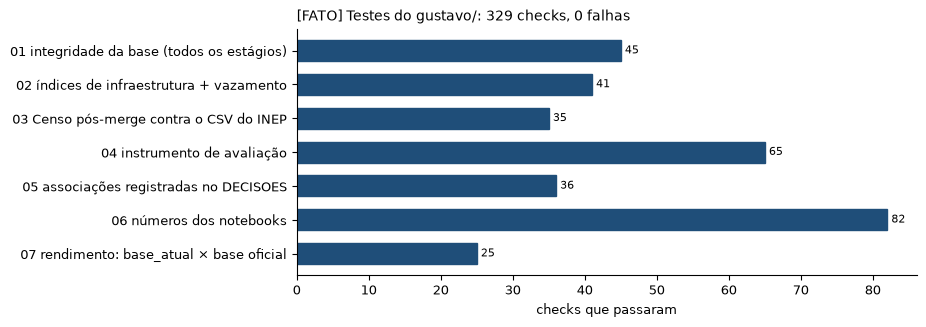

In [4]:
nomes = {
    "validacao_base.txt": "01 integridade da base (todos os estágios)",
    "validacao_indices.txt": "02 índices de infraestrutura + vazamento",
    "validacao_pos04.txt": "03 Censo pós-merge contra o CSV do INEP",
    "validacao_avaliacao.txt": "04 instrumento de avaliação",
    "validacao_associacoes.txt": "05 associações registradas no DECISOES",
    "validacao_descritivos.txt": "06 números dos notebooks",
    "validacao_sobreposicao.txt": "07 rendimento: base_atual × base oficial",
}
c = checks.assign(teste=checks["relatorio"].map(nomes)).dropna(subset=["teste"]).sort_values("teste")
fig, ax = plt.subplots(figsize=(8, 3.2))
F.barras_contagem(ax, c["teste"], c["ok"], ["funil"] * len(c))
ax.get_legend().remove()
ax.set_xlabel("checks que passaram")
F.titulo(ax, f"Testes do gustavo/: {c['ok'].sum()} checks, {c['falhas'].sum()} falhas", "FATO")
F.salvar(fig, FIGURAS, "00_checks_gustavo")
plt.show()

## 4. Ferramentas

| Camada | Ferramenta | Para quê |
|---|---|---|
| Linguagem e ambiente | Python 3.12 num único `.venv` (o do `abandono-escolar`), versões fixadas em dois `requirements.txt` | o `gustavo/` roda no mesmo `.venv` desde 03/11/2026; no Python global, os números mudavam |
| Dados | pandas + pyarrow (Parquet), openpyxl (`.xlsx`), xlrd (`.xls` de 2007–2011), odfpy | ler as planilhas do INEP e gravar as bases com tipos explícitos (regra 6) |
| Modelos e incerteza | scikit-learn **1.8.0** (Ridge, árvore, `Pipeline`), numpy, scipy | o 1.9.1 mudava o Random Forest da P026 em até 0,0036; fixado por decisão da pesquisadora |
| Figuras e notebooks | matplotlib, Jupyter (nbconvert), `src/figuras.py` | padrão único de figura: intervalo, linha do zero, marca aberta sem intervalo, nível no título |
| Testes | pytest (70 testes, sem rede e sem ler `dados/`) e scripts de checks do `gustavo/testes/` | cada número publicado tem um teste ou uma comparação |
| Versionamento | git em dois repositórios + junction NTFS; sha256 dos dados no manifesto | o código vai para o git; os dados não (regra 2), só os hashes |

In [5]:
def fixadas(caminho):
    pares = {}
    for linha in caminho.read_text(encoding="utf-8").splitlines():
        nome, _, versao = linha.split(";")[0].strip().partition("==")
        if versao:
            pares[nome.lower()] = versao
    return pares

oficial_req, dados_req = fixadas(ENTRADAS["req_oficial"]), fixadas(ENTRADAS["req_dados"])
chave = ["pandas", "pyarrow", "numpy", "openpyxl", "xlrd", "scikit-learn", "scipy", "matplotlib", "pytest", "nbconvert"]
pd.DataFrame([{"pacote": p, "versão fixada": oficial_req.get(p) or dados_req.get(p),
               "onde": "abandono-escolar/requirements.txt" if p in oficial_req else "Dados-do-Projeto/requirements.txt"}
              for p in chave])

,pacote,versão fixada,onde
0,pandas,3.0.5,abandono-escolar/requirements.txt
1,pyarrow,25.0.1,abandono-escolar/requirements.txt
2,numpy,2.5.3,abandono-escolar/requirements.txt
3,openpyxl,3.1.5,abandono-escolar/requirements.txt
4,xlrd,2.0.2,Dados-do-Projeto/requirements.txt
5,scikit-learn,1.8.0,Dados-do-Projeto/requirements.txt
6,scipy,1.18.1,Dados-do-Projeto/requirements.txt
7,matplotlib,3.11.1,abandono-escolar/requirements.txt
8,pytest,9.1.1,abandono-escolar/requirements.txt
9,nbconvert,7.17.1,abandono-escolar/requirements.txt


## 5. Linha do tempo das decisões

Cada ponto é uma entrada datada do `abandono-escolar/docs/DECISOES.md`. As decisões de desenho do orientador
(D1–D7) foram tomadas em 17/09/2026. As entradas foram escritas retroativamente em 03/11/2026, copiando as
fontes sem reinterpretar.

Marcos que não estão no `DECISOES.md`:

- **07–14/10/2026:** o Gustavo constrói o `gustavo/` (rendimento 2007–2025, 18 itens de infraestrutura,
  índices `zano`; `gustavo/docs/relatorio_01` a `05`).
- **14/10/2026:** os relatórios 00–07 de `Relatórios do Projeto/` ficam no estado que esta pasta atualiza.

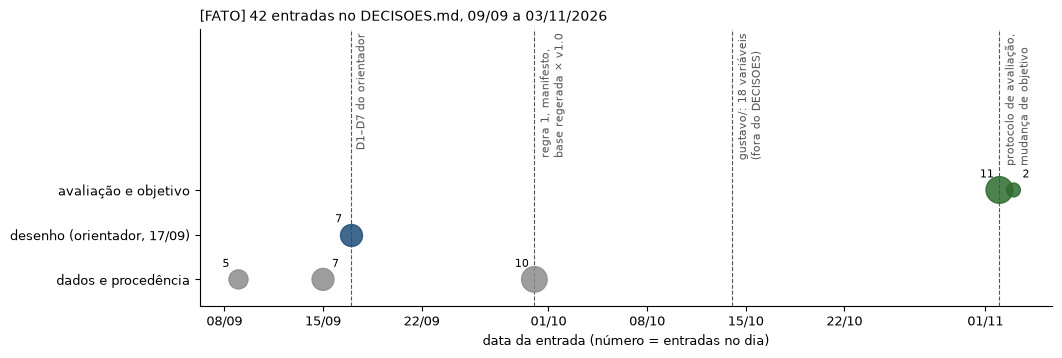

In [6]:
import matplotlib.dates as mdates
cats = ["dados e procedência", "desenho (orientador, 17/09)", "avaliação e objetivo"]
cores = {cats[0]: D.CINZA, cats[1]: D.AZUL, cats[2]: "#2e6b2e"}
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, cat in enumerate(cats):
    s = tempo[tempo["categoria"] == cat]
    por_dia = s.groupby("data").size()
    ax.scatter(por_dia.index, [i] * len(por_dia), s=40 + 30 * por_dia.values, color=cores[cat], alpha=0.85, zorder=3)
    for j, (dia, n) in enumerate(por_dia.items()):
        ax.annotate(f"{n}", (dia, i), xytext=(-9 if j % 2 == 0 else 9, 9), textcoords="offset points",
                    ha="center", fontsize=8)
marcos = {
    "2026-09-17": "D1–D7 do orientador",
    "2026-09-30": "regra 1, manifesto,\nbase regerada × v1.0",
    "2026-10-14": "gustavo/: 18 variáveis\n(fora do DECISOES)",
    "2026-11-02": "protocolo de avaliação,\nmudança de objetivo",
}
for dia, texto in marcos.items():
    F.eventos(ax, {pd.Timestamp(dia): texto})
ax.set_yticks(range(len(cats)), cats)
ax.set_ylim(-0.6, len(cats) + 2.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_xlabel("data da entrada (número = entradas no dia)")
F.titulo(ax, f"{len(tempo)} entradas no DECISOES.md, 09/09 a 03/11/2026", "FATO")
F.salvar(fig, FIGURAS, "00_linha_do_tempo_decisoes")
plt.show()

## 6. Ordem de leitura

**Para entender o projeto:** 00 → 01 → 02 → 03 desta pasta, nesta ordem; cada um supõe o anterior. Para
saber o que foi feito, o que está em aberto e o que vem depois: 04 → 06 → 07. O 05 é de consulta.

Depois:

1. `abandono-escolar/docs/SINTESE_DO_PROJETO.md`: o que foi medido, refutado e não se sabe, com níveis de
   evidência (com as ressalvas do notebook 06, §5);
2. `abandono-escolar/notebooks/01_leitura_e_recorte`, `02_descritivo` e `03_avaliacao`: as figuras de cada
   etapa, mais detalhadas que aqui;
3. `abandono-escolar/docs/DECISOES.md`: a decisão, a evidência e a alternativa descartada de cada escolha;
4. `gustavo/docs/relatorio_01` a `06`: o histórico da construção da base estendida.

**Para subir num NotebookLM** (com limite de arquivos): os oito notebooks exportados em HTML ou PDF, mais o
`SINTESE_DO_PROJETO.md` e o `DECISOES.md` do `abandono-escolar`. Com espaço, acrescentar o
`metodologia_variaveis.md` e o `CLAUDE.md`.

**Para rodar esta pasta** (da pasta `Dados-do-Projeto`, com o `.venv` do `abandono-escolar` ativado):

```bash
python "Contexto do Projeto/gerar_tabelas.py"
cd "Contexto do Projeto"
jupyter nbconvert --to notebook --execute --inplace 0*.ipynb
```

As entradas são as saídas já gravadas dos dois pipelines e da avaliação. Nada aqui baixa, regrava base ou
roda modelo.